# ESI-CIMMYT Analysis

## Imports and Settings

In [1]:
# Imports
import sqlite3
from pathlib import Path
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('classic')

pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 150)

## Data

In [ ]:
# Data
PATH_HOME = Path.home()
PATH_DATA = r"esi_cimmyt"
PATH_SQL_DB = PATH_HOME / PATH_DATA / r"data\processed\sql_db\cimmyt.db"
QUERY = """
SELECT 
    -- Index variables
    table_01_reference.farmer_id, 
    table_01_reference.plot_id, 
    table_01_reference.logbook_id, 
    table_01_reference.practice_id, 
    table_01_reference.year,

    -- ESI variables (absolute)
    table_12_esi_scores.esi_total,
    table_12_esi_scores.esi_land,
    table_12_esi_scores.esi_water,
    table_12_esi_scores.esi_climate,
    table_12_esi_scores.esi_climate_albedo,   
    
    -- ESI variables (intensity)
    table_12_esi_scores.total_esi_intensity_area,
    table_12_esi_scores.total_esi_intensity_revenue,
    table_12_esi_scores.climate_esi_intensity_area,
    table_12_esi_scores.water_esi_intensity_area,
    table_12_esi_scores.land_esi_intensity_area,

    -- Other numerical variables (agronomic, env. pressures)
    table_03_agronomic_features.maize_grain_yield_t_ha,
    table_03_agronomic_features.maize_forage_yield_t_ha,
    table_03_agronomic_features.area_ha,
    table_05_water_features.water_cons_hyb_ml_m3_ha,
    table_11_emissions_net_ghg.net_ghg_emissions_tco2eq_ha,

    -- Categorical variables
    table_01_reference.plot_type, 
    table_01_reference.practices_type,
    table_02_reference_enriched.hydric_regime,  
    table_02_reference_enriched.veg_type,  
    table_01_reference.conservation_agriculture,
    table_09_emissions_soc.ca_fao_dummy,

    --Flags
    table_05_water_features.water_use_source

FROM table_01_reference

LEFT JOIN table_02_reference_enriched USING (practice_id)
LEFT JOIN table_03_agronomic_features USING (practice_id)
LEFT JOIN table_05_water_features USING (practice_id)
LEFT JOIN table_09_emissions_soc USING (practice_id)
LEFT JOIN table_11_emissions_net_ghg USING (practice_id)
LEFT JOIN table_12_esi_scores USING (practice_id)
"""

conn = sqlite3.connect(PATH_SQL_DB)
data = pd.read_sql_query(QUERY, conn)
data.head()

,farmer_id,plot_id,logbook_id,practice_id,year,esi_total,esi_land,esi_water,esi_climate,esi_climate_albedo,total_esi_intensity_area,total_esi_intensity_revenue,climate_esi_intensity_area,water_esi_intensity_area,land_esi_intensity_area,maize_grain_yield_t_ha,maize_forage_yield_t_ha,area_ha,water_cons_hyb_ml_m3_ha,net_ghg_emissions_tco2eq_ha,plot_type,practices_type,hydric_regime,veg_type,conservation_agriculture,ca_fao_dummy,water_use_source
0,1,150477,141739,151844,2017,NaN,0.001989,0.0,NaN,-0.000162,NaN,NaN,NaN,0.0,0.198913,0.70,NaN,1.0,NaN,NaN,EXTENSION PLOT,INNOVATION,RAINFED,tropical forest,1.0,0,None
1,1,150477,226927,236071,2018,NaN,0.001989,0.0,NaN,-0.000162,NaN,NaN,NaN,0.0,0.198913,1.80,NaN,1.0,NaN,NaN,EXTENSION PLOT,INNOVATION,RAINFED,tropical forest,0.0,0,None
2,10,68692,67397,77279,2016,0.000639,0.000656,0.0,0.000031,-0.000048,0.063870,4.435386e-08,0.003135,0.0,0.065583,3.60,NaN,1.0,NaN,0.502374,EXTENSION PLOT,INNOVATION,RAINFED,warm climate grassland,0.0,0,None
3,100,9482,8747,11015,2012,0.000607,0.000656,0.0,0.000000,-0.000048,0.060735,NaN,0.000000,0.0,0.065583,0.01,NaN,1.0,NaN,0.000000,EXTENSION PLOT,INNOVATION,RAINFED,warm climate grassland,0.0,0,None
4,10000,78960,74628,84878,2016,0.000652,0.000710,0.0,0.000087,-0.000145,0.065156,3.619750e-08,0.008669,0.0,0.071031,6.00,NaN,1.0,NaN,1.389364,EXTENSION PLOT,INNOVATION,RAINFED,temperate forest,0.0,0,None


In [187]:
# Create extra intensity variable
sample = data.copy()

sample['total_yield_t_ha'] = sample[
    ['maize_grain_yield_t_ha', 'maize_forage_yield_t_ha']
].sum(axis=1, min_count=1)

sample['total_esi_intensity_yield'] = (
    sample['esi_total'].replace([np.inf, -np.inf], np.nan)
    / sample['total_yield_t_ha'].where(sample['total_yield_t_ha'] > 0)
)

# Set CA dummy as categorical
sample["ca_fao_dummy"] = sample["ca_fao_dummy"].astype("category")

# Broadcast conservation agriculture dummy at the logbook-year level
sample['conservation_agriculture'] = sample.groupby(['logbook_id', 'year'])['conservation_agriculture'].transform('max').astype("category")

In [188]:
# Filters
mask_sbs_plots = sample.plot_type.eq("SIDE-BY-SIDE COMPARISON")
mask_ext_plots = sample.plot_type.eq("EXTENSION PLOT")
mask_rainfed_zero = sample.hydric_regime.eq("RAINFED") & sample.esi_water.eq(0)
mask_irrigation_reported = sample.hydric_regime.eq("IRRIGATION") & sample.water_use_source.eq("observed")

In [189]:
# Samples
sample_full = sample.copy()
sample_sbs = sample[mask_sbs_plots].copy()
sample_ext = sample[mask_ext_plots].copy()
# sample_sbs_ml_issue_filter = sample.loc[mask_sbs_plots & (mask_rainfed_zero | mask_irrigation_reported)]

## Group Comparisons

### Visual comparisons

#### Conventional vs innovation

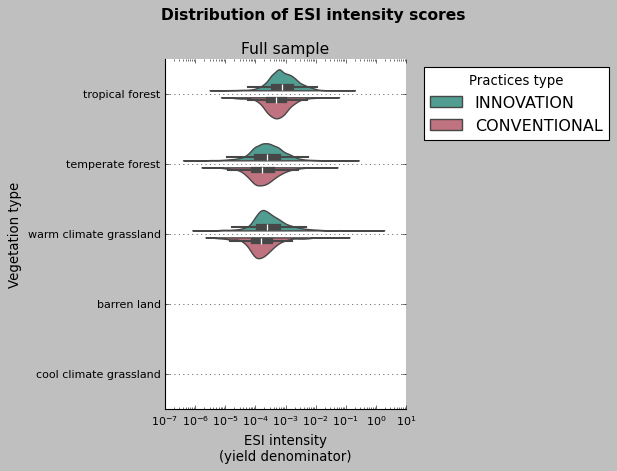

In [105]:
# Configure sample
sample_var = sample_full

# Set sample ids
sample_label_map = {
    id(sample_full): "Full sample",
    id(sample_sbs):  "Side-by-side sample",
    id(sample_ext):  "Extension sample",
}

sample_label = sample_label_map.get(id(sample_var), "Sample")

# Configure x-variable
esi_var = "total_esi_intensity_yield"

# Set x-labels
label_map = {
    "total_esi_intensity_revenue": "ESI intensity\n(revenue denominator)",
    "total_esi_intensity_area":    "ESI intensity\n(area denominator)",
    "total_esi_intensity_yield":    "ESI intensity\n(yield denominator)",
}

xlabel = label_map.get(esi_var, esi_var)

# Order vegetation type distributions by median ESI intensity
veg_order = (
    sample_var.groupby("veg_type")[esi_var]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

# Set colorblind palette (Paul Tol muted teal/rose)
palette = {"INNOVATION": "#44AA99", "CONVENTIONAL": "#CC6677"}

# Violinplot recipe
sns.violinplot(
    data=sample_var,
    x=esi_var,
    y="veg_type",
    log_scale=(True, False),
    split=True,
    gap=0.25,
    hue="practices_type",
    order=veg_order,
    palette=palette
)

plt.xlabel(xlabel, fontsize=12)
plt.ylabel("Vegetation type", fontsize=12)

plt.suptitle("Distribution of ESI intensity scores", fontsize=14, weight='bold')
plt.title(sample_label, fontsize=14)

plt.legend(title="Practices type", bbox_to_anchor=(1.04, 1), loc="upper left")

plt.grid(axis='y', linestyle=':')
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()


#### Conservation agriculture (FAO)

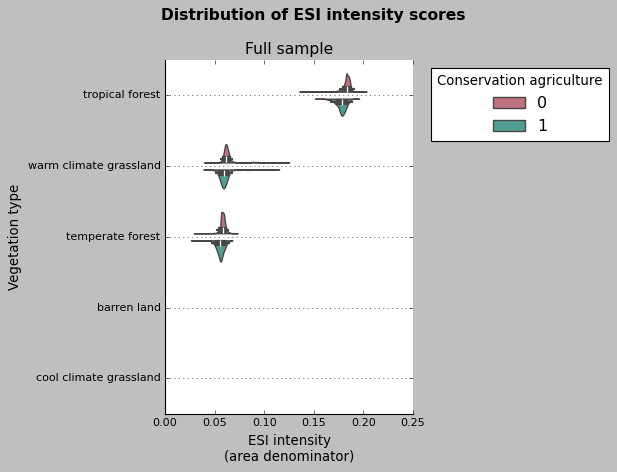

In [125]:
# Configure sample
sample_var = sample_full

# Set sample ids
sample_label_map = {
    id(sample_full): "Full sample",
    id(sample_sbs):  "Side-by-side sample",
    id(sample_ext):  "Extension sample",
}

sample_label = sample_label_map.get(id(sample_var), "Sample")

# Configure x-variable
esi_var = "total_esi_intensity_area"

# Set x-labels
label_map = {
    "total_esi_intensity_revenue": "ESI intensity\n(revenue denominator)",
    "total_esi_intensity_area":    "ESI intensity\n(area denominator)",
    "total_esi_intensity_yield":    "ESI intensity\n(yield denominator)",
}

xlabel = label_map.get(esi_var, esi_var)

# Order vegetation type distributions by median ESI intensity
veg_order = (
    sample_var.groupby("veg_type")[esi_var]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

# Set colorblind palette (Paul Tol muted teal/rose)
palette = {1: "#44AA99", 0: "#CC6677"}

# Violinplot recipe
sns.violinplot(
    data=sample_var,
    x=esi_var,
    y="veg_type",
    # log_scale=(True, False),
    split=True,
    gap=0.25,
    hue="ca_fao_dummy",
    order=veg_order,
    palette=palette
)

plt.xlabel(xlabel, fontsize=12)
plt.ylabel("Vegetation type", fontsize=12)

plt.suptitle("Distribution of ESI intensity scores", fontsize=14, weight='bold')
plt.title(sample_label, fontsize=14)

plt.legend(title="Conservation agriculture", bbox_to_anchor=(1.04, 1), loc="upper left")

plt.grid(axis='y', linestyle=':')
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

Text(0.5, 1.02, 'Distribution of ESI intensity scores')

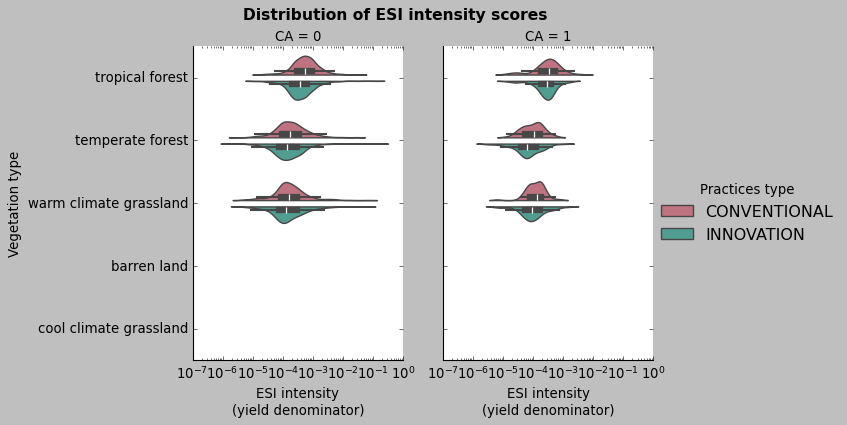

In [158]:
# Configure sample
sample_var = sample_sbs

# Set sample ids
sample_label_map = {
    id(sample_full): "Full sample",
    id(sample_sbs):  "Side-by-side sample",
    id(sample_ext):  "Extension sample",
}

sample_label = sample_label_map.get(id(sample_var), "Sample")

# Configure x-variable
esi_var = "total_esi_intensity_yield"

# Set x-labels
label_map = {
    "total_esi_intensity_revenue": "ESI intensity\n(revenue denominator)",
    "total_esi_intensity_area":    "ESI intensity\n(area denominator)",
    "total_esi_intensity_yield":    "ESI intensity\n(yield denominator)",
}

xlabel = label_map.get(esi_var, esi_var)

# Order vegetation type distributions by median ESI intensity
veg_order = (
    sample_var.groupby("veg_type")[esi_var]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

palette = {"INNOVATION": "#44AA99", "CONVENTIONAL": "#CC6677"}


# Plot recipe
g = sns.FacetGrid(
    data=sample_var,
    col="ca_fao_dummy",
    col_order=[0, 1],
    sharey=True, sharex=True,
    height=5, aspect=0.9
)
g.map_dataframe(
    sns.violinplot,
    x=esi_var,
    y="veg_type",
    hue="practices_type",
    log_scale=(True,False),
    split=True,
    gap=0.25,
    order=veg_order,
    palette=palette
)
g.add_legend(title="Practices type")
g.set_titles(col_template="CA = {col_name}")
g.set_axis_labels(xlabel, "Vegetation type")
g.figure.suptitle("Distribution of ESI intensity scores", fontsize=14, weight="bold", y=1.02)

Text(0.5, 1.02, 'Distribution of ESI intensity scores')

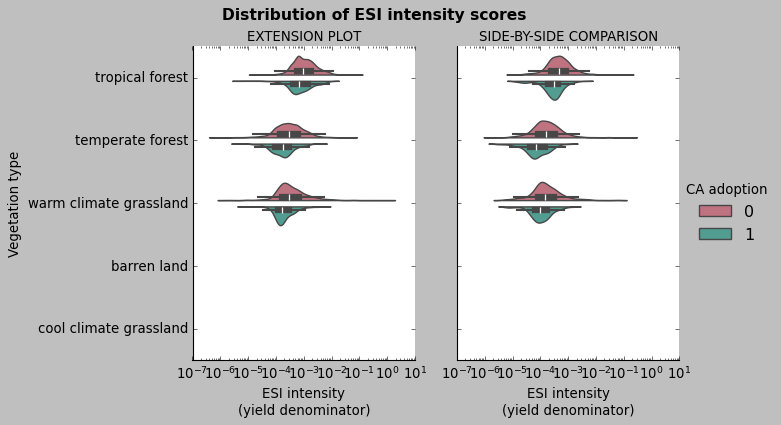

In [153]:
# Configure sample
sample_var = sample_full

# Set sample ids
sample_label_map = {
    id(sample_full): "Full sample",
    id(sample_sbs):  "Side-by-side sample",
    id(sample_ext):  "Extension sample",
}

sample_label = sample_label_map.get(id(sample_var), "Sample")

# Configure x-variable
esi_var = "total_esi_intensity_yield"

# Set x-labels
label_map = {
    "total_esi_intensity_revenue": "ESI intensity\n(revenue denominator)",
    "total_esi_intensity_area":    "ESI intensity\n(area denominator)",
    "total_esi_intensity_yield":    "ESI intensity\n(yield denominator)",
}

xlabel = label_map.get(esi_var, esi_var)

# Order vegetation type distributions by median ESI intensity
veg_order = (
    sample_var.groupby("veg_type")[esi_var]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

palette = {1: "#44AA99", 0: "#CC6677"}

g = sns.FacetGrid(
    data=sample_var,
    col="plot_type",
    # col_order=[0, 1],
    sharey=True, sharex=True,
    height=5, aspect=0.9
)
g.map_dataframe(
    sns.violinplot,
    x=esi_var,
    y="veg_type",
    hue="ca_fao_dummy",
    log_scale=(True,False),
    split=True,
    gap=0.25,
    order=veg_order,
    palette=palette
)
g.add_legend(title="CA adoption")
g.set_titles(col_template="{col_name}")
g.set_axis_labels(xlabel, "Vegetation type")
g.figure.suptitle("Distribution of ESI intensity scores", fontsize=14, weight="bold", y=1.02)

#### Conservation agriculture (CIMMYT)

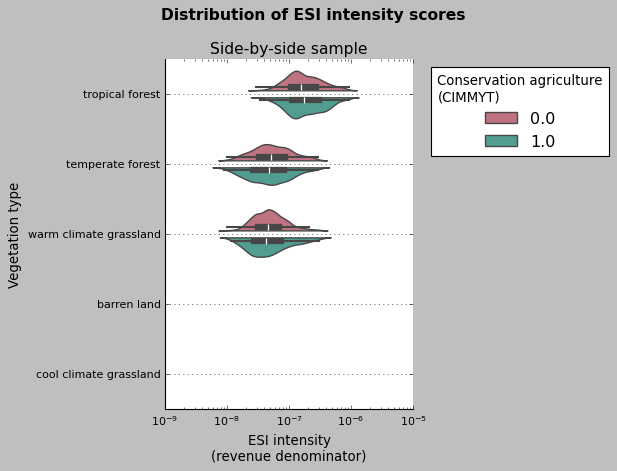

In [230]:
# Configure sample
sample_var = sample_sbs

# Set sample ids
sample_label_map = {
    id(sample_full): "Full sample",
    id(sample_sbs):  "Side-by-side sample",
    id(sample_ext):  "Extension sample",
}

sample_label = sample_label_map.get(id(sample_var), "Sample")

# Configure x-variable
esi_var = "total_esi_intensity_revenue"

# Set x-labels
label_map = {
    "total_esi_intensity_revenue": "ESI intensity\n(revenue denominator)",
    "total_esi_intensity_area":    "ESI intensity\n(area denominator)",
    "total_esi_intensity_yield":    "ESI intensity\n(yield denominator)",
}

xlabel = label_map.get(esi_var, esi_var)

# Order vegetation type distributions by median ESI intensity
veg_order = (
    sample_var.groupby("veg_type")[esi_var]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

# Set colorblind palette (Paul Tol muted teal/rose)
palette = {1: "#44AA99", 0: "#CC6677"}

# Violinplot recipe
sns.violinplot(
    data=sample_var,
    x=esi_var,
    y="veg_type",
    log_scale=(True, False),
    split=True,
    gap=0.25,
    hue="conservation_agriculture",
    order=veg_order,
    palette=palette
)

plt.xlabel(xlabel, fontsize=12)
plt.ylabel("Vegetation type", fontsize=12)

plt.suptitle("Distribution of ESI intensity scores", fontsize=14, weight='bold')
plt.title(sample_label, fontsize=14)

plt.legend(title="Conservation agriculture\n(CIMMYT)", bbox_to_anchor=(1.04, 1), loc="upper left")

plt.grid(axis='y', linestyle=':')
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

Text(0.5, 1.02, 'Distribution of ESI intensity scores')

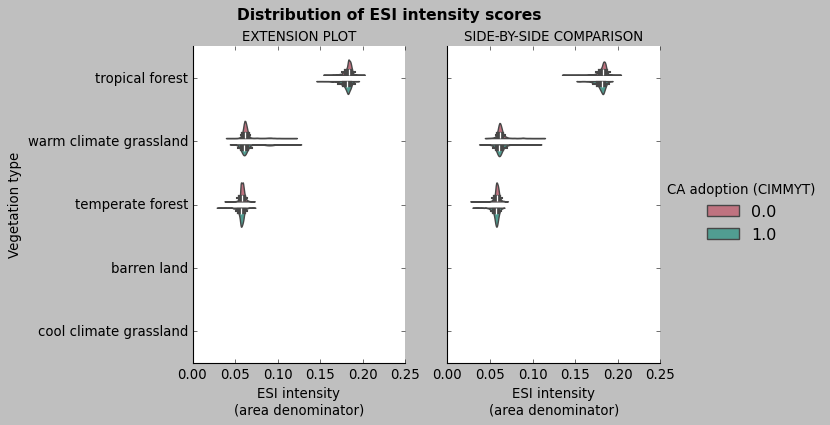

In [218]:
# Configure sample
sample_var = sample_full

# Set sample ids
sample_label_map = {
    id(sample_full): "Full sample",
    id(sample_sbs):  "Side-by-side sample",
    id(sample_ext):  "Extension sample",
}

sample_label = sample_label_map.get(id(sample_var), "Sample")

# Configure x-variable
esi_var = "total_esi_intensity_area"

# Set x-labels
label_map = {
    "total_esi_intensity_revenue": "ESI intensity\n(revenue denominator)",
    "total_esi_intensity_area":    "ESI intensity\n(area denominator)",
    "total_esi_intensity_yield":    "ESI intensity\n(yield denominator)",
}

xlabel = label_map.get(esi_var, esi_var)

# Order vegetation type distributions by median ESI intensity
veg_order = (
    sample_var.groupby("veg_type")[esi_var]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

palette = {1: "#44AA99", 0: "#CC6677"}

g = sns.FacetGrid(
    data=sample_var,
    col="plot_type",
    # col_order=[0, 1],
    sharey=True, sharex=True,
    height=5, aspect=0.9
)
g.map_dataframe(
    sns.violinplot,
    x=esi_var,
    y="veg_type",
    hue="conservation_agriculture",
    # log_scale=(True,False),
    split=True,
    gap=0.25,
    order=veg_order,
    palette=palette
)
g.add_legend(title="CA adoption (CIMMYT)")
g.set_titles(col_template="{col_name}")
g.set_axis_labels(xlabel, "Vegetation type")
g.figure.suptitle("Distribution of ESI intensity scores", fontsize=14, weight="bold", y=1.02)

Text(0.5, 1.02, 'Distribution of ESI intensity scores')

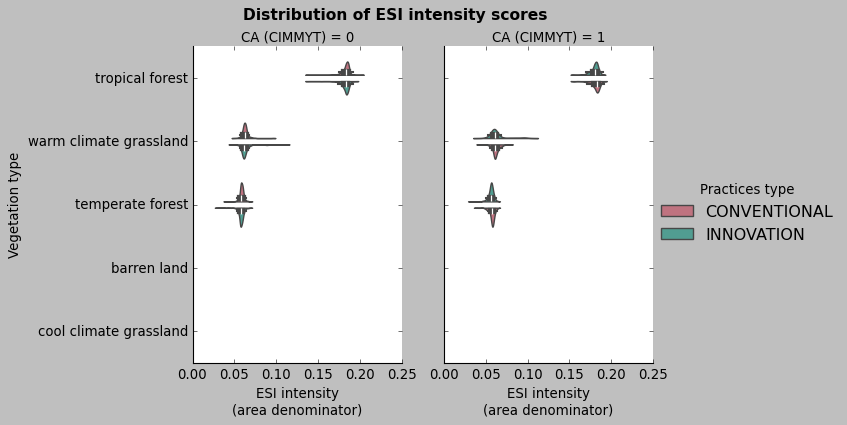

In [221]:
# Configure sample
sample_var = sample_sbs

# Set sample ids
sample_label_map = {
    id(sample_full): "Full sample",
    id(sample_sbs):  "Side-by-side sample",
    id(sample_ext):  "Extension sample",
}

sample_label = sample_label_map.get(id(sample_var), "Sample")

# Configure x-variable
esi_var = "total_esi_intensity_area"

# Set x-labels
label_map = {
    "total_esi_intensity_revenue": "ESI intensity\n(revenue denominator)",
    "total_esi_intensity_area":    "ESI intensity\n(area denominator)",
    "total_esi_intensity_yield":    "ESI intensity\n(yield denominator)",
}

xlabel = label_map.get(esi_var, esi_var)

# Order vegetation type distributions by median ESI intensity
veg_order = (
    sample_var.groupby("veg_type")[esi_var]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

palette = {"INNOVATION": "#44AA99", "CONVENTIONAL": "#CC6677"}


# Plot recipe
g = sns.FacetGrid(
    data=sample_var,
    col="conservation_agriculture",
    col_order=[0, 1],
    sharey=True, sharex=True,
    height=5, aspect=0.9
)
g.map_dataframe(
    sns.violinplot,
    x=esi_var,
    y="veg_type",
    hue="practices_type",
    # log_scale=(True,False),
    split=True,
    gap=0.25,
    order=veg_order,
    palette=palette
)
g.add_legend(title="Practices type")
g.set_titles(col_template="CA (CIMMYT) = {col_name}")
g.set_axis_labels(xlabel, "Vegetation type")
g.figure.suptitle("Distribution of ESI intensity scores", fontsize=14, weight="bold", y=1.02)

## Appendix

In [181]:
# Group by logbook and year, then count unique values for conservation agriculture
consistency_check = sample_full.groupby(['logbook_id', 'year'])['conservation_agriculture'].nunique()

# Identify groups where unique count is greater than 1
inconsistent_groups = consistency_check[consistency_check > 1]

if inconsistent_groups.empty:
    print("Success: All plot-year combinations are consistent.")
else:
    print("Consistency Error found in the following groups:")
    print(inconsistent_groups)

Success: All plot-year combinations are consistent.


In [88]:
# Summary to determine the appropriate scale for plotting
sample_var = sample_full
xvar = "total_esi_intensity_yield" 

print(f"Summary stats:\n{sample_var[xvar].describe()}")
print(f"Number of negative or zero values: {(sample_var[xvar] <= 0).sum()}")
print(f"Number of missing values: {sample_var[xvar].isna().sum()}")
print(f"Number of infinities: {np.isinf(sample_var[xvar]).sum()}")
print(f"Max-min ratio: {sample_var[xvar].max() / sample_var[xvar].min()}")

# esi_total -> logarithmic (max-min ratio > 100)
# esi_climate -> symlog (values <=0)
# esi_water -> symlog (values <=0)
# esi_land -> logarithmic (max-min ratio > 100)
# total_esi_intensity_area -> linear
# total_esi_intensity_revenue -> logarithmic
# total_esi_intensity_yield -> logarithmic

# go for symlog when plotting climate-water-land esi together

Summary stats:
count    2.338900e+04
mean     9.774359e-04
std      8.942169e-03
min      5.914165e-07
25%      1.562177e-04
50%      3.482483e-04
75%      8.033269e-04
max      1.214697e+00
Name: total_esi_intensity_yield, dtype: float64
Number of negative or zero values: 0
Number of missing values: 45305
Number of infinities: 0
Max-min ratio: 2053877.8640561919


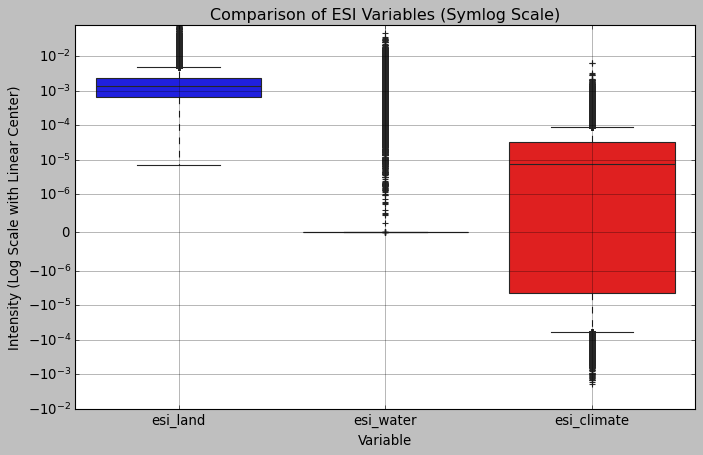

In [155]:
df_to_plot = pd.melt(sample_full[['esi_land', 'esi_water', 'esi_climate']], 
                       var_name='Variable', value_name='Intensity')

plt.figure(figsize=(10, 6))

sns.boxplot(data=df_to_plot, x='Variable', y='Intensity', hue='Variable')

plt.yscale('symlog', linthresh=1e-6, linscale=1)
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.ylabel("Intensity (Log Scale with Linear Center)")
plt.title("Comparison of ESI Variables (Symlog Scale)")
plt.show()